In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.base import clone

DATA_DIR = Path("C:\ML\data")
df = pd.read_csv(DATA_DIR / "diabetic_data.csv").replace("?", np.nan)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
y = (df["readmitted"] == "<30").astype(int)

groups = df["patient_nbr"]

X = df.drop(columns=[
    "readmitted",
    "encounter_id",
    "patient_nbr",
    "weight"
])

# Treat administrative ID fields as categorical
for col in [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]:
    X[col] = X[col].astype("object")

print("Predictor shape:", X.shape)
print("Positive cases:", y.sum())
print("Positive class percentage:", round(y.mean() * 100, 2))

Predictor shape: (101766, 46)
Positive cases: 11357
Positive class percentage: 11.16


In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

patient_overlap = len(
    set(train_groups) & set(test_groups)
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training positive rate:", round(y_train.mean(), 4))
print("Testing positive rate:", round(y_test.mean(), 4))
print("Patient overlap:", patient_overlap)

assert patient_overlap == 0

Training rows: 81613
Testing rows: 20153
Training positive rate: 0.1128
Testing positive rate: 0.1067
Patient overlap: 0


In [5]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created.")
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

Preprocessing pipeline created.
Numeric features: 8
Categorical features: 38


C:\Users\NEWLYN DABREO\AppData\Local\Temp\ipykernel_31296\2980041208.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [6]:
random_forest = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest and Extra Trees models created.")

Random Forest and Extra Trees models created.


In [7]:
print("Training Random Forest...")
random_forest.fit(X_train, y_train)
print("Random Forest training completed.")

print("\nTraining Extra Trees...")
extra_trees.fit(X_train, y_train)
print("Extra Trees training completed.")

Training Random Forest...
Random Forest training completed.

Training Extra Trees...
Extra Trees training completed.


In [8]:
def evaluate_model(name, model, X_test, y_test):

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = model.predict(X_test)

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    eligible = np.where(precision[:-1] >= 0.60)[0]

    recall_at_precision_60 = (
        float(recall[eligible].max())
        if len(eligible) > 0
        else np.nan
    )

    return {
        "Model": name,
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "Recall at Precision >= 0.60": recall_at_precision_60,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            zero_division=0
        )
    }


results = pd.DataFrame([
    evaluate_model(
        "Random Forest",
        random_forest,
        X_test,
        y_test
    ),
    evaluate_model(
        "Extra Trees",
        extra_trees,
        X_test,
        y_test
    )
])

display(results.round(4))

,Model,PR-AUC,ROC-AUC,Recall at Precision >= 0.60,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.2138,0.6797,0.0079,0.8750,0.2987,0.1269,0.1781
1,Extra Trees,0.2049,0.6644,0.0070,0.8555,0.2572,0.1874,0.2168


In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Dummy Classifier
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Logistic Regression
logistic_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=800,
        random_state=42
    ))
])

print("Training Dummy Classifier...")
dummy_model.fit(X_train, y_train)

print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Both baseline models trained successfully.")

Training Dummy Classifier...
Training Logistic Regression...
Both baseline models trained successfully.


In [10]:
all_results = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        dummy_model,
        X_test,
        y_test
    ),
    evaluate_model(
        "Logistic Regression",
        logistic_model,
        X_test,
        y_test
    ),
    evaluate_model(
        "Random Forest",
        random_forest,
        X_test,
        y_test
    ),
    evaluate_model(
        "Extra Trees",
        extra_trees,
        X_test,
        y_test
    )
])

display(
    all_results
    .sort_values("PR-AUC", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,PR-AUC,ROC-AUC,Recall at Precision >= 0.60,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.2138,0.6797,0.0079,0.8750,0.2987,0.1269,0.1781
1,Extra Trees,0.2049,0.6644,0.0070,0.8555,0.2572,0.1874,0.2168
2,Logistic Regression,0.2023,0.6579,0.0023,0.6549,0.1672,0.5611,0.2577
3,Dummy Classifier,0.1067,0.5000,NaN,0.8933,0.0000,0.0000,0.0000


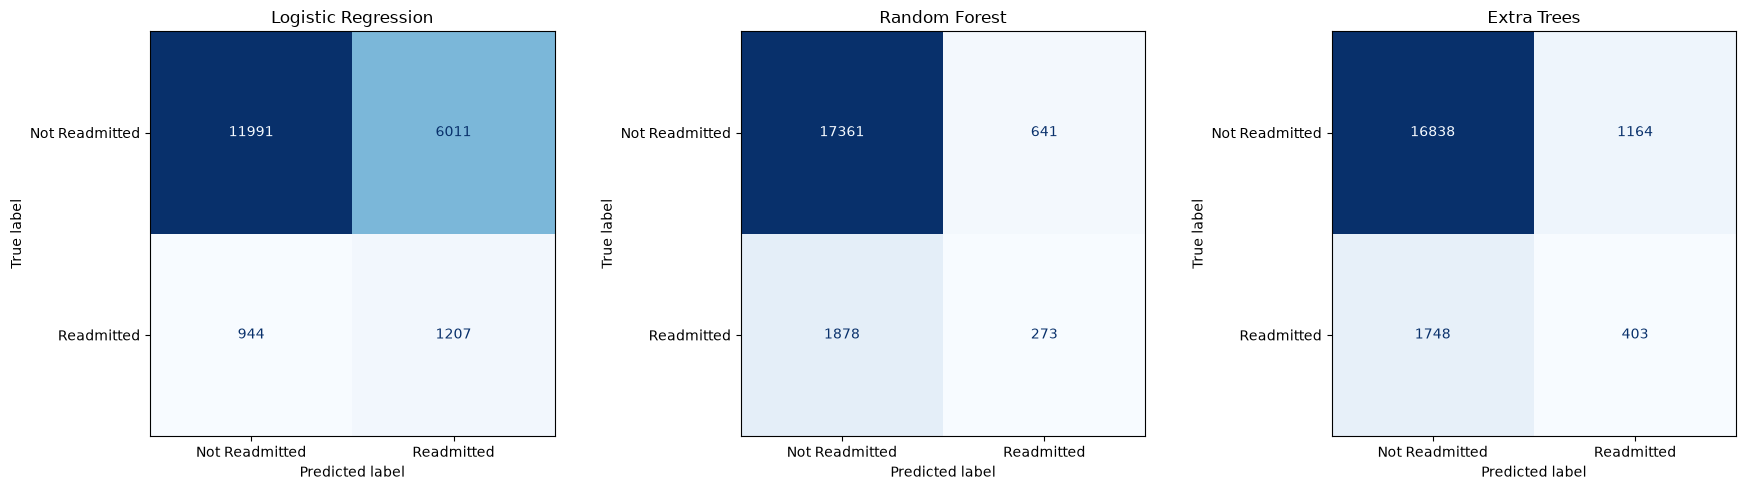

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):

    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions)

    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Readmitted", "Readmitted"]
    )

    cm_display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


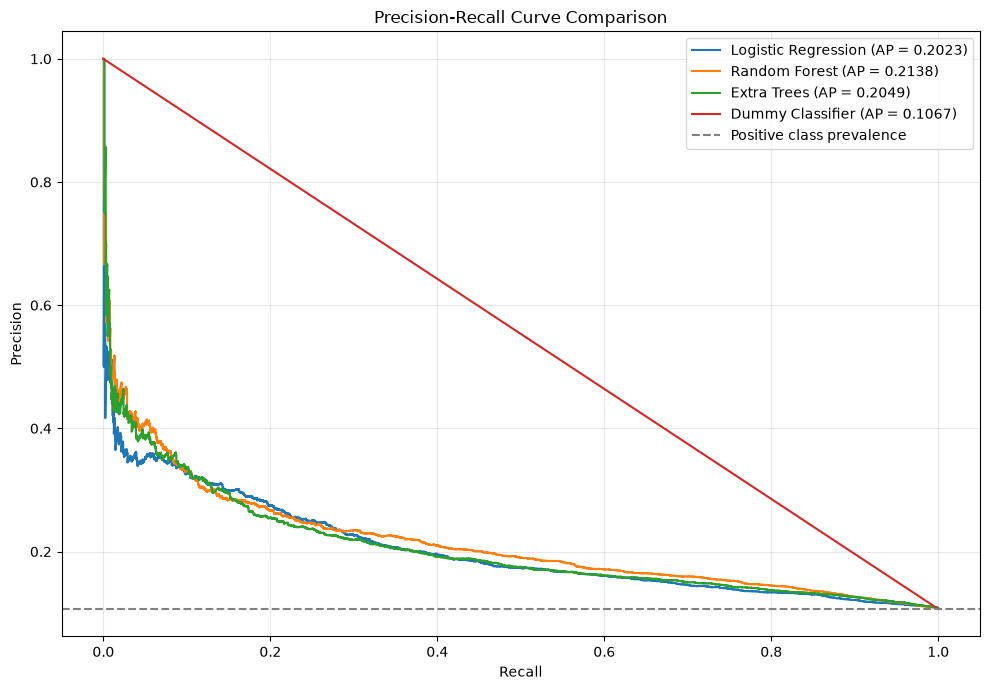

In [15]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees,
    "Dummy Classifier": dummy_model
}

plt.figure(figsize=(10, 7))

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {pr_auc:.4f})"
    )

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Positive class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Feature,Importance
6,numeric__number_inpatient,0.06127
1,numeric__num_lab_procedures,0.04629
3,numeric__num_medications,0.04316
0,numeric__time_in_hospital,0.03331
7,numeric__number_diagnoses,0.02544
2,numeric__num_procedures,0.02317
5,numeric__number_emergency,0.01579
34,categorical__discharge_disposition_id_1,0.01545
4,numeric__number_outpatient,0.01384
43,categorical__discharge_disposition_id_11,0.01197


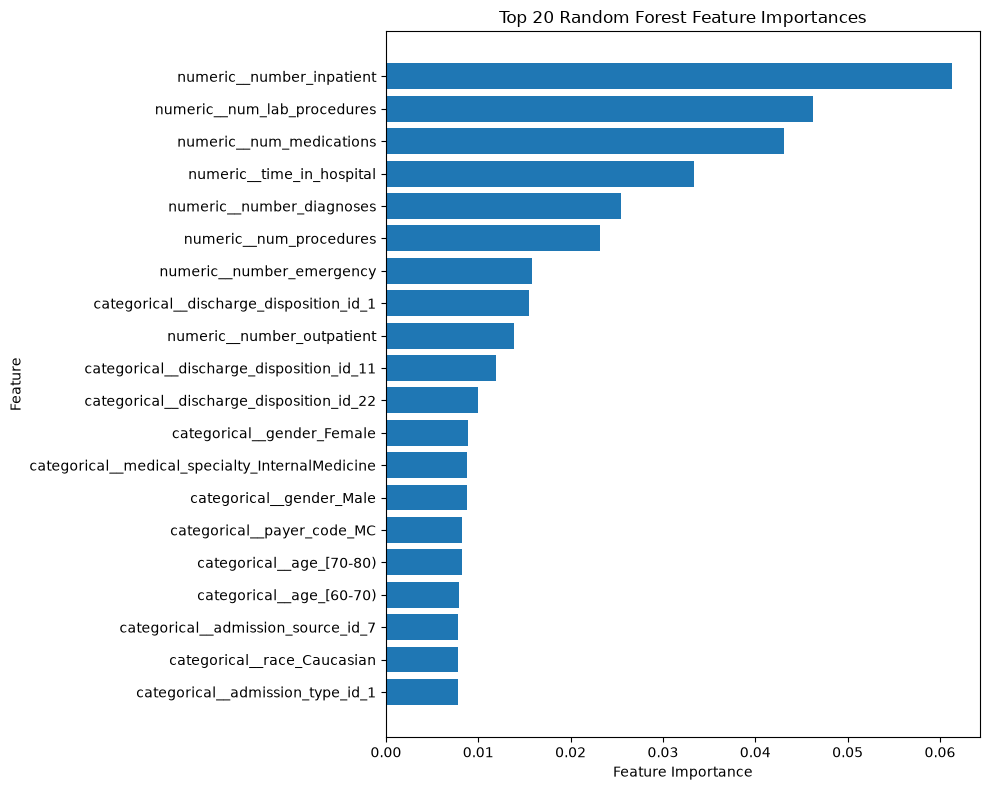

In [18]:
from IPython.display import display as show_table

# Extract fitted preprocessing and classifier
rf_preprocessor = random_forest.named_steps["preprocessing"]
rf_classifier = random_forest.named_steps["classifier"]

# Get transformed feature names
feature_names = rf_preprocessor.get_feature_names_out()

# Extract feature importance
importance_values = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
top_features = feature_importance.head(20)

show_table(top_features.round(5))

# Visualisation
plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

In [20]:
from IPython.display import display as show_table
from sklearn.metrics import classification_report, confusion_matrix

error_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees
}

error_summary = []

for name, model in error_models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    error_summary.append({
        "Model": name,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn
    })

    print(f"\nClassification Report: {name}")

    print(classification_report(
        y_test,
        predictions,
        target_names=["Not Readmitted", "Readmitted"],
        zero_division=0
    ))

error_summary_df = pd.DataFrame(error_summary)

print("\nError Analysis Summary:")

show_table(error_summary_df)


Classification Report: Logistic Regression
                precision    recall  f1-score   support

Not Readmitted       0.93      0.67      0.78     18002
    Readmitted       0.17      0.56      0.26      2151

      accuracy                           0.65     20153
     macro avg       0.55      0.61      0.52     20153
  weighted avg       0.85      0.65      0.72     20153


Classification Report: Random Forest
                precision    recall  f1-score   support

Not Readmitted       0.90      0.96      0.93     18002
    Readmitted       0.30      0.13      0.18      2151

      accuracy                           0.88     20153
     macro avg       0.60      0.55      0.56     20153
  weighted avg       0.84      0.88      0.85     20153


Classification Report: Extra Trees
                precision    recall  f1-score   support

Not Readmitted       0.91      0.94      0.92     18002
    Readmitted       0.26      0.19      0.22      2151

      accuracy                    

,Model,True Positives,False Positives,True Negatives,False Negatives
0,Logistic Regression,1207,6011,11991,944
1,Random Forest,273,641,17361,1878
2,Extra Trees,403,1164,16838,1748


In [21]:
from IPython.display import display as show_table

rf_predictions = random_forest.predict(X_test)

rf_probabilities = random_forest.predict_proba(X_test)[:, 1]

error_analysis = X_test.copy()

error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = rf_predictions
error_analysis["Readmission_Probability"] = rf_probabilities

false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

print("\nFalse positive examples:")
show_table(false_positives.head(10))

print("\nFalse negative examples:")
show_table(false_negatives.head(10))

False positives: 641
False negatives: 1878

False positive examples:


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,Actual,Predicted,Readmission_Probability
81,AfricanAmerican,Male,[50-60),1,6,7,3,NaN,NaN,52,...,No,No,No,No,No,No,No,0,1,0.504770
175,Caucasian,Female,[70-80),1,3,7,11,NaN,InternalMedicine,44,...,No,No,No,No,No,Ch,Yes,0,1,0.533294
410,AfricanAmerican,Female,[40-50),1,1,7,2,NaN,NaN,36,...,No,No,No,No,No,No,Yes,0,1,0.519727
734,Caucasian,Male,[30-40),2,1,2,3,NaN,NaN,51,...,No,No,No,No,No,No,Yes,0,1,0.532422
1101,Caucasian,Male,[60-70),6,10,1,8,NaN,NaN,23,...,No,No,No,No,No,Ch,Yes,0,1,0.513173
1525,AfricanAmerican,Female,[70-80),1,2,7,11,NaN,InternalMedicine,67,...,No,No,No,No,No,Ch,Yes,0,1,0.501736
1918,Caucasian,Male,[80-90),3,5,1,5,NaN,Surgery-General,32,...,No,No,No,No,No,No,Yes,0,1,0.505861
2183,AfricanAmerican,Female,[70-80),1,5,7,1,NaN,NaN,37,...,No,No,No,No,No,No,Yes,0,1,0.510494
2348,AfricanAmerican,Female,[40-50),2,1,2,2,NaN,NaN,39,...,No,No,No,No,No,No,Yes,0,1,0.513257
2428,Caucasian,Male,[40-50),2,1,20,2,NaN,NaN,12,...,No,No,No,No,No,No,Yes,0,1,0.549146



False negative examples:


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,Actual,Predicted,Readmission_Probability
46,Caucasian,Female,[70-80),3,5,4,9,NaN,InternalMedicine,25,...,No,No,No,No,No,Ch,Yes,1,0,0.497171
50,AfricanAmerican,Male,[50-60),2,1,2,4,NaN,NaN,40,...,No,No,No,No,No,No,No,1,0,0.187193
116,Caucasian,Male,[60-70),1,2,7,4,NaN,NaN,65,...,No,No,No,No,No,No,Yes,1,0,0.326158
162,Caucasian,Male,[80-90),6,3,7,5,NaN,NaN,47,...,No,No,No,No,No,No,No,1,0,0.402100
172,Caucasian,Male,[70-80),3,2,4,6,NaN,Cardiology,31,...,No,No,No,No,No,Ch,Yes,1,0,0.428753
343,Caucasian,Female,[60-70),1,1,7,6,NaN,Cardiology,60,...,No,No,No,No,No,No,Yes,1,0,0.375952
424,AfricanAmerican,Male,[80-90),6,25,7,3,NaN,InternalMedicine,47,...,No,No,No,No,No,No,Yes,1,0,0.348267
444,Caucasian,Male,[80-90),6,3,1,3,NaN,NaN,56,...,No,No,No,No,No,No,No,1,0,0.316781
628,Caucasian,Male,[60-70),1,1,1,8,NaN,Family/GeneralPractice,46,...,No,No,No,No,No,No,Yes,1,0,0.452048
699,AfricanAmerican,Female,[50-60),2,1,2,2,NaN,NaN,44,...,No,No,No,No,No,Ch,Yes,1,0,0.249696


In [24]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_quick = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__max_depth": [15, 25],
    "classifier__min_samples_leaf": [2]
}

quick_search = GridSearchCV(
    rf_quick,
    param_grid,
    scoring="average_precision",
    cv=GroupKFold(n_splits=2),
    n_jobs=1,
    verbose=2
)

quick_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

best_rf_model = quick_search.best_estimator_

print("Best parameters:")
print(quick_search.best_params_)

print("Best validation PR-AUC:")
print(round(quick_search.best_score_, 4))


Fitting 2 folds for each of 4 candidates, totalling 8 fits
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=2, classifier__n_estimators=100; total time=   4.3s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=2, classifier__n_estimators=100; total time=   5.0s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=2, classifier__n_estimators=150; total time=   5.7s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=2, classifier__n_estimators=150; total time=   5.6s
[CV] END classifier__max_depth=25, classifier__min_samples_leaf=2, classifier__n_estimators=100; total time=   6.9s
[CV] END classifier__max_depth=25, classifier__min_samples_leaf=2, classifier__n_estimators=100; total time=   6.7s
[CV] END classifier__max_depth=25, classifier__min_samples_leaf=2, classifier__n_estimators=150; total time=   9.2s
[CV] END classifier__max_depth=25, classifier__min_samples_leaf=2, classifier__n_estimators=150; total time=   9.0s
Best paramete

In [25]:
tuned_rf_results = evaluate_model(
    "Tuned Random Forest",
    best_rf_model,
    X_test,
    y_test
)

print("Tuned Random Forest Test Results:")

show_table(
    pd.DataFrame([tuned_rf_results]).round(4)
)

Tuned Random Forest Test Results:


,Model,PR-AUC,ROC-AUC,Recall at Precision >= 0.60,Accuracy,Precision,Recall,F1-score
0,Tuned Random Forest,0.1988,0.6714,0.0079,0.6759,0.1747,0.5467,0.2647


In [26]:
final_models = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees,
    "Tuned Random Forest": best_rf_model
}

final_results = pd.DataFrame([
    evaluate_model(name, model, X_test, y_test)
    for name, model in final_models.items()
])

final_results = final_results.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Final Milestone 3 Model Comparison:")

show_table(final_results.round(4))

Final Milestone 3 Model Comparison:


,Model,PR-AUC,ROC-AUC,Recall at Precision >= 0.60,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.2138,0.6797,0.0079,0.8750,0.2987,0.1269,0.1781
1,Extra Trees,0.2049,0.6644,0.0070,0.8555,0.2572,0.1874,0.2168
2,Logistic Regression,0.2023,0.6579,0.0023,0.6549,0.1672,0.5611,0.2577
3,Tuned Random Forest,0.1988,0.6714,0.0079,0.6759,0.1747,0.5467,0.2647
4,Dummy Classifier,0.1067,0.5000,NaN,0.8933,0.0000,0.0000,0.0000


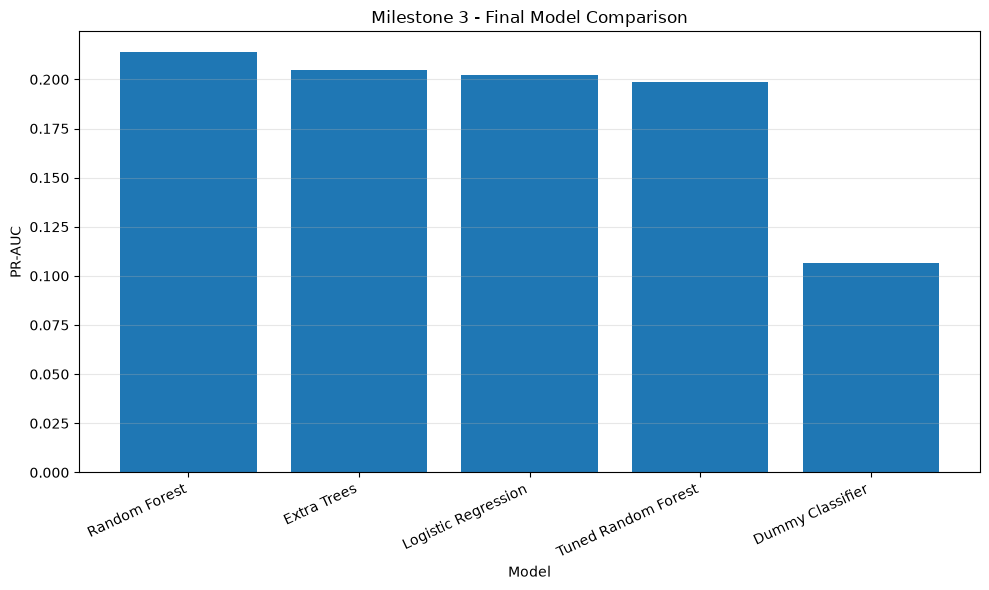

In [27]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_results["Model"],
    final_results["PR-AUC"]
)

plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.title("Milestone 3 - Final Model Comparison")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()